In [1]:
import numpy as np
import pandas as pd

# ---- Generate a synthetic bank-loan dataset (no dataset was provided) ----
rng = np.random.default_rng(42)
n = 5000

application_date = pd.Timestamp("2022-01-01") + pd.to_timedelta(rng.integers(0, 1400, n), unit="D")
age = rng.integers(21, 66, n)
education = rng.choice(["High School", "Graduate", "Post Graduate", "Doctorate"], n, p=[0.35, 0.40, 0.20, 0.05])
edu_level = pd.Series(education).map({"High School": 0, "Graduate": 1, "Post Graduate": 2, "Doctorate": 3}).values
employment_type = rng.choice(["Salaried", "Self-employed", "Business", "Unemployed"], n, p=[0.55, 0.20, 0.17, 0.08])
home_ownership = rng.choice(["Rent", "Own", "Mortgage"], n, p=[0.45, 0.25, 0.30])
loan_purpose = rng.choice(["Home", "Car", "Education", "Personal", "Business"], n, p=[0.20, 0.25, 0.15, 0.25, 0.15])
employment_years = np.clip(np.round(rng.normal((age - 21) * 0.5, 4)), 0, 40)
employment_years[employment_type == "Unemployed"] = 0
annual_income = np.round(rng.lognormal(np.log(450000) + 0.25 * edu_level + 0.01 * employment_years, 0.55) / 1000) * 1000
annual_income[employment_type == "Unemployed"] = np.round(annual_income[employment_type == "Unemployed"] * 0.3, -3)
credit_score = np.clip(np.round(rng.normal(680 + 3 * employment_years / 4 + 10 * edu_level, 60)), 300, 850)
num_existing_loans = rng.poisson(1.2, n).clip(0, 6)
loan_term_months = rng.choice([12, 24, 36, 60], n, p=[0.15, 0.30, 0.35, 0.20])
purpose_mult = pd.Series(loan_purpose).map({"Home": 2.0, "Car": 1.0, "Education": 0.8, "Personal": 0.5, "Business": 1.5}).values
loan_amount = np.round(annual_income * purpose_mult * (0.6 + (credit_score - 600) / 800) *
                       (loan_term_months / 36) ** 0.5 * rng.lognormal(0, 0.25, n) / 1000) * 1000
loan_amount = np.clip(loan_amount, 20000, None)

# Default risk: low credit score, high loan-to-income, many loans, unemployed, renting, personal loans
ratio = loan_amount / annual_income
z = (-1.6 - (credit_score - 680) / 45 + 0.45 * np.log(ratio) + 0.30 * num_existing_loans
     - 0.04 * employment_years - 0.15 * edu_level
     + 0.6 * (employment_type == "Unemployed") + 0.35 * (home_ownership == "Rent")
     + 0.4 * (loan_purpose == "Personal") + 0.2 * (loan_term_months == 60))
defaulted = (rng.random(n) < 1 / (1 + np.exp(-z))).astype(int)

df = pd.DataFrame({
    "applicant_id": [f"APP{100000 + i}" for i in range(n)],
    "application_date": application_date.strftime("%Y-%m-%d"),
    "age": age, "education": education, "employment_type": employment_type,
    "employment_years": employment_years, "annual_income": annual_income,
    "home_ownership": home_ownership, "credit_score": credit_score,
    "num_existing_loans": num_existing_loans, "loan_purpose": loan_purpose,
    "loan_term_months": loan_term_months, "loan_amount": loan_amount,
    "defaulted": defaulted})

# Add realistic missing values
for col, k in [("annual_income", 150), ("employment_years", 200), ("credit_score", 250),
               ("employment_type", 120), ("home_ownership", 80)]:
    df.loc[rng.choice(n, k, replace=False), col] = np.nan

df.to_csv("loan_data.csv", index=False)
print("Saved loan_data.csv:", df.shape)

# ---- From here on we work with the CSV, like a trainer-given file ----
df = pd.read_csv("loan_data.csv")
print("\nColumn types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("\nDuplicates:", df.duplicated().sum())
print("Default rate:", round(df["defaulted"].mean(), 3))

Saved loan_data.csv: (5000, 14)

Column types:
applicant_id              str
application_date          str
age                     int64
education                 str
employment_type           str
employment_years      float64
annual_income         float64
home_ownership            str
credit_score          float64
num_existing_loans      int64
loan_purpose              str
loan_term_months        int64
loan_amount           float64
defaulted               int64
dtype: object

Missing values:
employment_type     120
employment_years    200
annual_income       150
home_ownership       80
credit_score        250
dtype: int64

Duplicates: 0
Default rate: 0.186


## task1 -concepts,splits and leakage

Train 3000 | Val 1000 | Test 1000 (test set put aside)
Default rate - train 0.187 | val 0.186 | test 0.186
Depth    1: train 0.81  val 0.81
Depth    3: train 0.85  val 0.83
Depth    5: train 0.85  val 0.83
Depth   10: train 0.92  val 0.80
Depth None: train 1.00  val 0.74


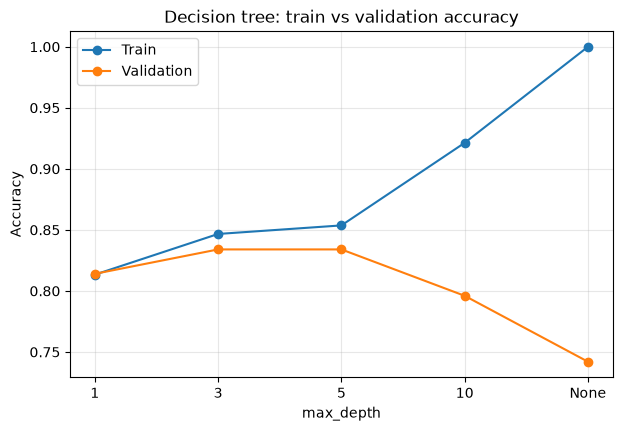

In [2]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier

y = df["defaulted"]
X = df.drop(columns=["defaulted", "applicant_id"])       # ID is not a feature

# 60 / 20 / 20 split, stratified, random_state=42
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)   # 0.25 x 80% = 20%

print(f"Train {len(X_train)} | Val {len(X_val)} | Test {len(X_test)} (test set put aside)")
print(f"Default rate - train {y_train.mean():.3f} | val {y_val.mean():.3f} | test {y_test.mean():.3f}")

# Overfitting demo: numeric columns only for Task 1 (full preprocessing comes in Task 2)
num_cols_t1 = ["age", "employment_years", "annual_income", "credit_score",
               "num_existing_loans", "loan_term_months", "loan_amount"]

depths = [1, 3, 5, 10, None]
train_acc, val_acc = [], []
for d in depths:
    tree = make_pipeline(SimpleImputer(strategy="median"),
                         DecisionTreeClassifier(max_depth=d, random_state=42))
    tree.fit(X_train[num_cols_t1], y_train)
    train_acc.append(tree.score(X_train[num_cols_t1], y_train))
    val_acc.append(tree.score(X_val[num_cols_t1], y_val))
    print(f"Depth {str(d):>4}: train {train_acc[-1]:.2f}  val {val_acc[-1]:.2f}")

labels = [str(d) for d in depths]
plt.figure(figsize=(7, 4.5))
plt.plot(labels, train_acc, marker="o", label="Train")
plt.plot(labels, val_acc, marker="o", label="Validation")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Decision tree: train vs validation accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("t1_overfitting.png", dpi=150, bbox_inches="tight")
plt.show()

In [3]:
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# ---- 5-fold cross-validation (train + validation data, test set untouched) ----
lr_pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                        LogisticRegression(max_iter=1000))
cv_scores = cross_val_score(lr_pipe, X_temp[num_cols_t1], y_temp, cv=5)
print("CV scores:", cv_scores.round(3))
print(f"CV: {cv_scores.mean():.2f} +/- {cv_scores.std():.2f}")

# ---- Data leakage demo ----
# WRONG: learn median + scaling from train AND validation together (= scaling before the split)
both = pd.concat([X_train[num_cols_t1], X_val[num_cols_t1]])
imp_wrong = SimpleImputer(strategy="median").fit(both)
sc_wrong = StandardScaler().fit(imp_wrong.transform(both))
prep = lambda d: sc_wrong.transform(imp_wrong.transform(d[num_cols_t1]))
wrong = LogisticRegression(max_iter=1000).fit(prep(X_train), y_train).score(prep(X_val), y_val)

# RIGHT: pipeline learns median + scaling from TRAIN only, then applies them to validation
right = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                      LogisticRegression(max_iter=1000)) \
            .fit(X_train[num_cols_t1], y_train).score(X_val[num_cols_t1], y_val)

print(f"\nLeaky (scaled before split) val accuracy: {wrong:.3f}")
print(f"Correct (fit on train only)  val accuracy: {right:.3f}")

CV scores: [0.838 0.839 0.841 0.836 0.846]
CV: 0.84 +/- 0.00

Leaky (scaled before split) val accuracy: 0.837
Correct (fit on train only)  val accuracy: 0.837


### Results
- Split (stratified, random_state=42): train 3000 / validation 1000 / test 1000; default rate 18.6% in each. Test set put aside until the final evaluation.
- Overfitting: Depth 1: train 0.81 val 0.81 | Depth 3: 0.85 / 0.83 | Depth 5: 0.85 / 0.83 | Depth 10: 0.92 / 0.80 | Depth None: train 1.00 val 0.74. Depth 3-5 is the sweet spot; deeper trees memorise the training data and get worse on new data.
- Logistic Regression 5-fold CV: 0.84 +/- 0.00 (fold scores 0.836-0.846).

### Data leakage (4 lines)
1. Leaky way: the imputer and scaler learned their medians/means from train + validation together, so information from the evaluation rows leaked into training.
2. Correct way: a Pipeline learns them from the training rows only and just applies them to validation; in cross-validation this is repeated inside every fold.
3. Here both gave 0.837, because medians and means barely change when 1000 extra rows are added - the leak is real but tiny.
4. With stronger leaks (e.g. a column only known after default) the leaky score can look much better than real performance, so preprocessing must always be fitted on training data only.

### Supervised or unsupervised?
- **Spam detection - supervised:** emails are labelled spam / not spam.
- **Customer segmentation - unsupervised:** no labels; the model groups similar customers.
- **House price prediction - supervised:** past sale prices are the labels (regression).
- **Anomaly detection - usually unsupervised:** the model learns what "normal" looks like and flags unusual cases (supervised if past anomalies are labelled).

### ML workflow (7 steps)
1. **Define the problem** - what to predict and how success is measured (e.g. predict loan default, measured by ROC-AUC / recall).
2. **Collect the data** - gather applicant records with the known outcome.
3. **Clean and explore** - fix missing values, wrong types, duplicates; look for patterns.
4. **Split** - train / validation / test, with the test set locked away.
5. **Prepare features and train** - encoding, scaling, new features and models inside a pipeline.
6. **Evaluate and tune** - cross-validation, the right metrics, hyperparameter tuning, threshold choice.
7. **Deploy and monitor** - save the model, predict for new applicants, retrain when data changes.